
# Método de Newton

**Algoritmo 2.3 de Burden — Ejemplo 1**

En este ejemplo vamos a encontrar una raíz de la siguiente ecuación:

$$
f(x)=\cos x-x=0
$$



## 1. Fórmula del método

El método de Newton sirve para aproximar una raíz usando la función y su derivada:

$$
p=p_0-\frac{f(p_0)}{f'(p_0)}
$$

En este ejercicio tenemos:

$$
f(x)=\cos x-x,\qquad f'(x)=-\sin x-1
$$

Usaremos $p_0=\pi/4$ como valor inicial, igual que en el libro. El método se detiene cuando $|p-p_0|<TOL$ o cuando se llega al máximo de iteraciones.



## 2. Importar las funciones

Usamos `cos`, `sin` y `pi` para los cálculos trigonométricos. También importamos `matplotlib` para hacer la gráfica.


In [1]:

from math import cos, sin, pi
import matplotlib.pyplot as plt



## 3. Definir la función y su derivada

Con `def` creamos una función y con `return` indicamos qué resultado debe devolver.


In [2]:

def f(x):
    return cos(x) - x

def derivada(x):
    return -sin(x) - 1



## 4. Código del método de Newton

En cada iteración se calcula una nueva aproximación. Si la derivada vale cero, el método no puede seguir con ese cálculo.


In [3]:

def newton(p0, tol, nmax):
    datos = []

    for i in range(1, nmax + 1):
        df = derivada(p0)

        if df == 0:
            return None, datos, False

        p = p0 - f(p0) / df
        diferencia = abs(p - p0)
        datos.append((i, p, f(p), diferencia))

        if diferencia < tol:
            return p, datos, True

        p0 = p

    return p, datos, False



## 5. Resolver el ejemplo

Tomamos $p_0=\pi/4$, una tolerancia de $TOL=10^{-5}$ y un máximo de 100 iteraciones.


In [4]:

p0 = pi / 4
tol = 1e-5
nmax = 100

raiz, datos, exito = newton(p0, tol, nmax)

print("Iteración       p_n             f(p_n)        Diferencia")
print(f"    0       {p0:.10f}          {f(p0):.3e}          ---")

for i, p, valor_f, diferencia in datos:
    print(f"{i:5d}       {p:.10f}       {valor_f:.3e}       {diferencia:.3e}")

print()
if exito:
    print(f"Raíz aproximada: {raiz:.10f}")
    print(f"f(raíz) = {f(raiz):.3e}")
else:
    print("El método no alcanzó la tolerancia.")


Iteración       p_n             f(p_n)        Diferencia
    0       0.7853981634          -7.829e-02          ---
    1       0.7395361335       -7.549e-04       4.586e-02
    2       0.7390851781       -7.513e-08       4.510e-04
    3       0.7390851332       -7.772e-16       4.489e-08

Raíz aproximada: 0.7390851332
f(raíz) = -7.772e-16



## 6. Gráfica

La gráfica permite ver la función y la raíz aproximada que se obtuvo.


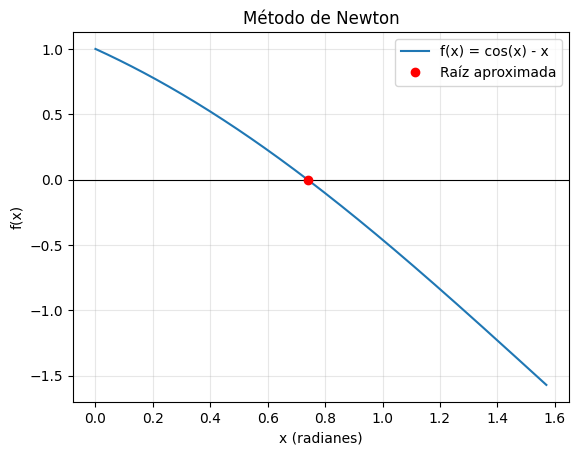

In [5]:

x = [i * (pi / 2) / 299 for i in range(300)]
y = [f(valor) for valor in x]

plt.plot(x, y, label="f(x) = cos(x) - x")
plt.axhline(0, color="black", linewidth=0.8)
plt.plot(raiz, f(raiz), "ro", label="Raíz aproximada")
plt.xlabel("x (radianes)")
plt.ylabel("f(x)")
plt.title("Método de Newton")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()



## 7. Resultado

La raíz aproximada es:

$$
\boxed{p\approx 0.739085}
$$

El resultado es cercano al del ejemplo de Burden. Los cálculos trigonométricos se hacen en radianes.

